# 00 — Données et audit initial
**Consigne :** test officiel scellé jusqu’à F. Le fichier test est téléchargé, mais ses labels ne servent pas à sélectionner un modèle. Les suppressions de doublons train–test servent uniquement à prévenir la contamination, pas à ajuster les modèles.

In [1]:
from pathlib import Path
import os, sys, re, time, random, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for d in ["data", "results", "predictions", "figures"]:
    (ROOT / d).mkdir(exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"
print("Racine:", ROOT, "| GPU:", DEVICE)


def report(y, p, threshold=0.5):
    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)
    pred = (p >= threshold).astype(int)
    return dict(
        accuracy=accuracy_score(y, pred),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        f1_sarc=f1_score(y, pred, zero_division=0),
        macro_f1=f1_score(y, pred, average="macro", zero_division=0),
        pr_auc=average_precision_score(y, p),
    )


def best_threshold(y, p):
    t = np.linspace(0.05, 0.95, 91)
    return float(
        t[np.argmax([f1_score(y, np.asarray(p) >= x, zero_division=0) for x in t])]
    )


def save_result(
    model, split, y, p, threshold, seconds=0, params=0, seed=SEED, preprocess=""
):
    row = dict(
        model=model,
        split=split,
        seed=seed,
        threshold=threshold,
        seconds=round(seconds, 2),
        trainable_parameters=params,
        preprocess=preprocess,
        **report(y, p, threshold),
    )
    path = ROOT / "results/results.csv"
    old = pd.read_csv(path) if path.exists() else pd.DataFrame()
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print(row)


def save_preds(model, seed, df, p, t):
    pd.DataFrame(
        {
            "id": df.id.to_numpy(),
            "y_true": df.y.to_numpy(),
            "y_pred": (np.asarray(p) >= t).astype(int),
            "prob_sarc": p,
        }
    ).to_csv(ROOT / f"predictions/{model}_seed{seed}.csv", index=False)

Racine: /kaggle/working | GPU: cuda


In [2]:
BASE = "https://raw.githubusercontent.com/iabufarha/ArSarcasm-v2/main/ArSarcasm-v2/"
for filename in ["training_data.csv", "testing_data.csv"]:
    path = ROOT / "data" / filename
    if not path.exists():
        pd.read_csv(BASE + filename).to_csv(path, index=False)
full = pd.read_csv(ROOT / "data/training_data.csv")
official_test = pd.read_csv(ROOT / "data/testing_data.csv")
print("Colonnes:", full.columns.tolist())
print(full.head(3).to_string(index=False))

Colonnes: ['tweet', 'sarcasm', 'sentiment', 'dialect']
                                                                                                                                tweet  sarcasm sentiment dialect
"د. #محمود_العلايلي:أرى أن الفريق #أحمد_شفيق رقم مهم في المعادلة السياسية المصرية ولا يمكن إغفالههل ترى أن هذا صحيح؟#أربعة_زائد_واحد"    False       NEU     msa
                                                                                  "مع فيدرر يا آجا والكبار 😍 https://t.co/hrBeHbkBNu"    False       NEU     msa
              “الداعون لمبدأ الاختلاط بين الجنسين؛ كالداعين لإلغاء التسعيرة كلاهما يريد تصفية السوق السوداء بجعلها حرة.”  #الاختلاط       True       NEG     msa


In [3]:
from sklearn.model_selection import train_test_split

full["id"] = np.arange(len(full))
official_test["id"] = np.arange(len(official_test))


def label(v):
    return str(v).strip().lower() in ("true", "1", "yes")


for d in [full, official_test]:
    d["tweet"] = d["tweet"].fillna("").astype(str)
    d["y"] = d["sarcasm"].map(label).astype(int)
train, val = train_test_split(
    full, test_size=0.10, random_state=42, stratify=full.sarcasm
)
train = train.copy()
val = val.copy()
print("30 exemples bruts train:")
print(train[["tweet", "sarcasm"]].head(30).to_string(index=False))
print("30 exemples bruts test (audit uniquement):")
print(official_test[["tweet"]].head(30).to_string(index=False))

30 exemples bruts train:
                                                                                                                                                                                                                                                                   tweet  sarcasm
                                                                                                                                   "#لافروف: #موسكو تأمل بإجراء حوار بناء بشأن الأزمة في #سورية خلال لقائي مع وزيري خارجية #إيران و #تركيا غداً https://t.co/m2ejSZD6WP"    False
                                                                                                                            "RT @jalalyw: @EHSANFAKEEH تفصيل الخبر لمن يريدالإستزادة والإطلاع 10دورسينما ف مصرستعرض فيلماعن بطولات قاسم سليماني ف العراق وسوريامن إنتا…"    False
                                                                                                                                                    تحدثن

In [4]:
import unicodedata

PATTERNS = {
    "url": r"https?://\S+|www\.\S+",
    "mention": r"@\w+",
    "hashtag": r"#\w+",
    "rires": r"(?:ه){3,}|(?:خ){3,}",
    "ponctuation_repetee": r"[!?؟،.]{2,}",
    "diacritiques": r"[\u064b-\u065f]",
    "tatweel": r"ـ",
    "lettres_repetees": r"([\u0621-\u064a])\1{2,}",
    "latin": r"[A-Za-z]",
    "chiffres_indiens": r"[٠-٩]",
    "emoji": r"[\U0001F300-\U0001FAFF]",
}


def normalize(s):
    s = re.sub(r"[\u064b-\u065fـ]", "", s)
    s = re.sub("[إأآٱ]", "ا", s)
    s = s.replace("ى", "ي")
    return re.sub(r"\s+", " ", s).strip()


def audit(df):
    out = {k: df.tweet.str.contains(v, regex=True).sum() for k, v in PATTERNS.items()}
    return pd.Series(out, name="nombre")


print(pd.DataFrame({"train": audit(train), "test": audit(official_test)}))
print(
    "Doublons exacts train/test:",
    train.tweet.duplicated().sum(),
    official_test.tweet.duplicated().sum(),
)
print("Doublons normalisés:", train.tweet.map(normalize).duplicated().sum())
print(
    "Contradictions train:",
    train.groupby(train.tweet.map(normalize)).y.nunique().gt(1).sum(),
)
print(
    "Présents dans test:",
    train.tweet.map(normalize).isin(set(official_test.tweet.map(normalize))).sum(),
)
# Ne jamais supprimer val/test. Retirer du train les chevauchements avec le test et val.
train = train.loc[
    ~train.tweet.map(normalize).isin(
        set(official_test.tweet.map(normalize)) | set(val.tweet.map(normalize))
    )
].copy()
# Politique de doublons contradictoires: supprimer TOUS les exemples de groupes contradictoires dans train.
conflict = train.groupby(train.tweet.map(normalize)).y.transform("nunique") > 1
print("Exemples contradictoires retirés:", conflict.sum())
train = train.loc[~conflict].copy()
train.to_csv(ROOT / "data/train.csv", index=False)
val.to_csv(ROOT / "data/val.csv", index=False)
print("Train final:", len(train), "Validation:", len(val))

/tmp/ipykernel_48/1768658226.py:26: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  out = {k: df.tweet.str.contains(v, regex=True).sum() for k, v in PATTERNS.items()}


                     train  test
url                   4302   440
mention               2638    23
hashtag               5333   987
rires                  140   101
ponctuation_repetee   2040   826
diacritiques          1340   587
tatweel                514   219
lettres_repetees       508   382
latin                 6253   718
chiffres_indiens       276    77
emoji                 1202   409
Doublons exacts train/test: 54 4
Doublons normalisés: 55
Contradictions train: 13
Présents dans test: 2
Exemples contradictoires retirés: 27
Train final: 11256 Validation: 1255


**À présenter :** indiquer l’artefact de format réellement observé (à inspecter visuellement), ses fréquences et son association avec les labels. Ne pas inventer son identité.

# A — Déséquilibre, raccourcis, baseline

In [5]:
from pathlib import Path
import os, sys, re, time, random, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for d in ["data", "results", "predictions", "figures"]:
    (ROOT / d).mkdir(exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"
print("Racine:", ROOT, "| GPU:", DEVICE)


def report(y, p, threshold=0.5):
    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)
    pred = (p >= threshold).astype(int)
    return dict(
        accuracy=accuracy_score(y, pred),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        f1_sarc=f1_score(y, pred, zero_division=0),
        macro_f1=f1_score(y, pred, average="macro", zero_division=0),
        pr_auc=average_precision_score(y, p),
    )


def best_threshold(y, p):
    t = np.linspace(0.05, 0.95, 91)
    return float(
        t[np.argmax([f1_score(y, np.asarray(p) >= x, zero_division=0) for x in t])]
    )


def save_result(
    model, split, y, p, threshold, seconds=0, params=0, seed=SEED, preprocess=""
):
    row = dict(
        model=model,
        split=split,
        seed=seed,
        threshold=threshold,
        seconds=round(seconds, 2),
        trainable_parameters=params,
        preprocess=preprocess,
        **report(y, p, threshold),
    )
    path = ROOT / "results/results.csv"
    old = pd.read_csv(path) if path.exists() else pd.DataFrame()
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print(row)


def save_preds(model, seed, df, p, t):
    pd.DataFrame(
        {
            "id": df.id.to_numpy(),
            "y_true": df.y.to_numpy(),
            "y_pred": (np.asarray(p) >= t).astype(int),
            "prob_sarc": p,
        }
    ).to_csv(ROOT / f"predictions/{model}_seed{seed}.csv", index=False)

Racine: /kaggle/working | GPU: cuda


In [6]:
train=pd.read_csv(ROOT/'data/train.csv'); val=pd.read_csv(ROOT/'data/val.csv')
print(len(train),len(val))

11256 1255


In [7]:
print('Taux global:',train.y.mean(),val.y.mean())
for field in ['dialect','sentiment']:
 print(field); print(train.groupby(field).y.agg(['size','mean']))
p0=np.zeros(len(val)); print('Jamais sarcastique:',report(val.y,p0))

Taux global: 0.17190831556503197 0.17290836653386454
dialect
         size      mean
dialect                
egypt    2409  0.345787
gulf      574  0.249129
levant    568  0.213028
magreb     38  0.394737
msa      7667  0.107343
sentiment
           size      mean
sentiment                
NEG        4128  0.418605
NEU        5155  0.029874
POS        1973  0.026863
Jamais sarcastique: {'accuracy': 0.8270916334661355, 'precision': 0.0, 'recall': 0.0, 'f1_sarc': 0.0, 'macro_f1': 0.45268207588312254, 'pr_auc': np.float64(0.17290836653386454)}


In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion
from sklearn.linear_model import LogisticRegression

start = time.time()
vec = FeatureUnion(
    [
        ("mots", TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_features=80000)),
        (
            "chars",
            TfidfVectorizer(
                analyzer="char", ngram_range=(2, 5), min_df=2, max_features=120000
            ),
        ),
    ]
)
X = vec.fit_transform(train.tweet.map(normalize))
V = vec.transform(val.tweet.map(normalize))
clf = LogisticRegression(max_iter=1000, class_weight="balanced")
clf.fit(X, train.y)
p = clf.predict_proba(V)[:, 1]
t = best_threshold(val.y, p)
save_result(
    "tfidf_logreg",
    "val",
    val.y,
    p,
    t,
    time.time() - start,
    len(clf.coef_[0]),
    preprocess="normalize",
)
import joblib

joblib.dump((vec, clf, t), ROOT / "results/baseline.joblib")

{'model': 'tfidf_logreg', 'split': 'val', 'seed': 42, 'threshold': 0.57, 'seconds': 10.83, 'trainable_parameters': 149024, 'preprocess': 'normalize', 'accuracy': 0.846215139442231, 'precision': 0.5625, 'recall': 0.4976958525345622, 'f1_sarc': 0.5281173594132029, 'macro_f1': 0.7181281704253069, 'pr_auc': np.float64(0.5283161219406253)}


['/kaggle/working/results/baseline.joblib']

In [9]:
for name,pat in [('URL',r'https?://\S+|www\.\S+'),('mention',r'@\w+'),('artefact_a_adapter',r'^RT ')]:
 for d in [train,val]:
  flag=d.tweet.str.contains(pat,regex=True)
  print(name,'n=',flag.sum(),'taux sarcastique avec/sans=',d.groupby(flag).y.mean().to_dict())
 flag=val.tweet.str.contains(pat,regex=True).astype(int)
 print('Règle',name,report(val.y,flag))

URL n= 4296 taux sarcastique avec/sans= {False: 0.2377873563218391, True: 0.06517690875232775}
URL n= 499 taux sarcastique avec/sans= {False: 0.2328042328042328, True: 0.08216432865731463}
Règle URL {'accuracy': 0.49482071713147413, 'precision': 0.08216432865731463, 'recall': 0.1889400921658986, 'f1_sarc': 0.11452513966480447, 'macro_f1': 0.38056245834968205, 'pr_auc': np.float64(0.1557631796539634)}
mention n= 2611 taux sarcastique avec/sans= {False: 0.17432041642567958, True: 0.1639218690157028}
mention n= 301 taux sarcastique avec/sans= {False: 0.16352201257861634, True: 0.2026578073089701}
Règle mention {'accuracy': 0.6844621513944223, 'precision': 0.2026578073089701, 'recall': 0.28110599078341014, 'f1_sarc': 0.23552123552123552, 'macro_f1': 0.518363027399172, 'pr_auc': np.float64(0.18127111255820297)}
artefact_a_adapter n= 101 taux sarcastique avec/sans= {False: 0.17229941730165846, True: 0.12871287128712872}
artefact_a_adapter n= 20 taux sarcastique avec/sans= {False: 0.172469635

# B — Zero-shot NLI et heuristique sentiment (aucun entraînement)

In [10]:
from pathlib import Path
import os, sys, re, time, random, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for d in ["data", "results", "predictions", "figures"]:
    (ROOT / d).mkdir(exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"
print("Racine:", ROOT, "| GPU:", DEVICE)


def report(y, p, threshold=0.5):
    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)
    pred = (p >= threshold).astype(int)
    return dict(
        accuracy=accuracy_score(y, pred),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        f1_sarc=f1_score(y, pred, zero_division=0),
        macro_f1=f1_score(y, pred, average="macro", zero_division=0),
        pr_auc=average_precision_score(y, p),
    )


def best_threshold(y, p):
    t = np.linspace(0.05, 0.95, 91)
    return float(
        t[np.argmax([f1_score(y, np.asarray(p) >= x, zero_division=0) for x in t])]
    )


def save_result(
    model, split, y, p, threshold, seconds=0, params=0, seed=SEED, preprocess=""
):
    row = dict(
        model=model,
        split=split,
        seed=seed,
        threshold=threshold,
        seconds=round(seconds, 2),
        trainable_parameters=params,
        preprocess=preprocess,
        **report(y, p, threshold),
    )
    path = ROOT / "results/results.csv"
    old = pd.read_csv(path) if path.exists() else pd.DataFrame()
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print(row)


def save_preds(model, seed, df, p, t):
    pd.DataFrame(
        {
            "id": df.id.to_numpy(),
            "y_true": df.y.to_numpy(),
            "y_pred": (np.asarray(p) >= t).astype(int),
            "prob_sarc": p,
        }
    ).to_csv(ROOT / f"predictions/{model}_seed{seed}.csv", index=False)

Racine: /kaggle/working | GPU: cuda


In [11]:
train = pd.read_csv(ROOT / "data/train.csv")
val = pd.read_csv(ROOT / "data/val.csv")
print(len(train), len(val))

11256 1255


In [12]:
from transformers import pipeline

zs = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=0 if DEVICE == "cuda" else -1,
)
configs = [
    ("ar", ["ساخرة", "جادة"], "هذه التغريدة {}."),
    ("fr", ["sarcastique", "sérieuse"], "Cette publication est {}."),
    ("en", ["sarcastic", "serious"], "This tweet is {}."),
]
for language, labels, template in configs:
    start = time.time()
    probs = []
    for tweet in val.tweet:
        r = zs(tweet, candidate_labels=labels, hypothesis_template=template)
        probs.append(dict(zip(r["labels"], r["scores"]))[labels[0]])
    probs = np.array(probs)
    np.save(ROOT / f"results/nli_{language}_val.npy", probs)
    threshold = best_threshold(val.y, probs)
    save_result("NLI_" + language, "val", val.y, probs, threshold, time.time() - start)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


{'model': 'NLI_ar', 'split': 'val', 'seed': 42, 'threshold': 0.82, 'seconds': 66.05, 'trainable_parameters': 0, 'preprocess': '', 'accuracy': 0.6804780876494024, 'precision': 0.2899543378995434, 'recall': 0.5852534562211982, 'f1_sarc': 0.38778625954198476, 'macro_f1': 0.5858068764017201, 'pr_auc': np.float64(0.3379393278122176)}
{'model': 'NLI_fr', 'split': 'val', 'seed': 42, 'threshold': 0.8599999999999999, 'seconds': 63.09, 'trainable_parameters': 0, 'preprocess': '', 'accuracy': 0.6956175298804781, 'precision': 0.3076923076923077, 'recall': 0.6082949308755761, 'f1_sarc': 0.4086687306501548, 'macro_f1': 0.6018665541662791, 'pr_auc': np.float64(0.34873314201380634)}
{'model': 'NLI_en', 'split': 'val', 'seed': 42, 'threshold': 0.82, 'seconds': 64.22, 'trainable_parameters': 0, 'preprocess': '', 'accuracy': 0.6892430278884463, 'precision': 0.30296127562642367, 'recall': 0.6129032258064516, 'f1_sarc': 0.4054878048780488, 'macro_f1': 0.5975659089115163, 'pr_auc': np.float64(0.340314809655

In [13]:
sa=pipeline('text-classification',model='CAMeL-Lab/bert-base-arabic-camelbert-da-sentiment',device=0 if DEVICE=='cuda' else -1)
print('IMPORTANT labels:',sa.model.config.id2label)
outputs=sa(val.tweet.tolist(),batch_size=16,truncation=True)
# Vérifier la correspondance NEG dans la configuration du modèle.
p=np.array([float(str(o['label']).lower() in ('negative','neg')) for o in outputs])
print('Labels renvoyés:',pd.Series([o['label'] for o in outputs]).value_counts())
save_result('sentiment_negatif_regle','val',val.y,p,.5)

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  436MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/86.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

vocab.txt:   0%|          | 0.00/305k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

IMPORTANT labels: {0: 'positive', 1: 'negative', 2: 'neutral'}
Labels renvoyés: negative    509
neutral     469
positive    277
Name: count, dtype: int64
{'model': 'sentiment_negatif_regle', 'split': 'val', 'seed': 42, 'threshold': 0.5, 'seconds': 0, 'trainable_parameters': 0, 'preprocess': '', 'accuracy': 0.6908366533864542, 'precision': 0.3320235756385069, 'recall': 0.7788018433179723, 'f1_sarc': 0.465564738292011, 'macro_f1': 0.6240379745271715, 'pr_auc': np.float64(0.29682758468448456)}


**Contamination possible :** le modèle de sentiment a été entraîné sur des jeux qui peuvent recouper ArSarcasm-v2. À mentionner dans le rapport.

# C — Embeddings statiques, BiLSTM, attention, mini-Transformer et déséquilibre
**AraVec :** télécharger manuellement le modèle Twitter unigrammes depuis la source AraVec officielle et renseigner son chemin. Ne pas utiliser des embeddings fictifs comme si c’était AraVec.

In [14]:
from pathlib import Path
import os, sys, re, time, random, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for d in ["data", "results", "predictions", "figures"]:
    (ROOT / d).mkdir(exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"
print("Racine:", ROOT, "| GPU:", DEVICE)


def report(y, p, threshold=0.5):
    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)
    pred = (p >= threshold).astype(int)
    return dict(
        accuracy=accuracy_score(y, pred),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        f1_sarc=f1_score(y, pred, zero_division=0),
        macro_f1=f1_score(y, pred, average="macro", zero_division=0),
        pr_auc=average_precision_score(y, p),
    )


def best_threshold(y, p):
    t = np.linspace(0.05, 0.95, 91)
    return float(
        t[np.argmax([f1_score(y, np.asarray(p) >= x, zero_division=0) for x in t])]
    )


def save_result(
    model, split, y, p, threshold, seconds=0, params=0, seed=SEED, preprocess=""
):
    row = dict(
        model=model,
        split=split,
        seed=seed,
        threshold=threshold,
        seconds=round(seconds, 2),
        trainable_parameters=params,
        preprocess=preprocess,
        **report(y, p, threshold),
    )
    path = ROOT / "results/results.csv"
    old = pd.read_csv(path) if path.exists() else pd.DataFrame()
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print(row)


def save_preds(model, seed, df, p, t):
    pd.DataFrame(
        {
            "id": df.id.to_numpy(),
            "y_true": df.y.to_numpy(),
            "y_pred": (np.asarray(p) >= t).astype(int),
            "prob_sarc": p,
        }
    ).to_csv(ROOT / f"predictions/{model}_seed{seed}.csv", index=False)

Racine: /kaggle/working | GPU: cuda


In [15]:
train = pd.read_csv(ROOT / "data/train.csv")
val = pd.read_csv(ROOT / "data/val.csv")
print(len(train), len(val))

11256 1255


In [16]:
import torch
from torch import nn
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from collections import Counter
from sklearn.utils.class_weight import compute_class_weight

TOKEN = re.compile(r"\S+")


def words(s):
    return TOKEN.findall(normalize(s))


cnt = Counter(w for s in train.tweet for w in words(s))
vocab = {"<pad>": 0, "<unk>": 1}
for w, f in cnt.items():
    if f >= 2:
        vocab[w] = len(vocab)
MAXLEN = 64


def encode(s):
    a = [vocab.get(w, 1) for w in words(s)][:MAXLEN]
    return a + [0] * (MAXLEN - len(a))


def oov(df):
    toks = [w for s in df.tweet for w in words(s)]
    return sum(w not in vocab for w in toks) / max(1, len(toks))


print("Vocabulaire:", len(vocab), "OOV validation:", oov(val))


class TweetDS(Dataset):
    def __init__(self, df):
        self.x = torch.tensor([encode(s) for s in df.tweet], dtype=torch.long)
        self.y = torch.tensor(df.y.to_numpy(), dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.x[i], self.y[i]


trds = TweetDS(train)
vads = TweetDS(val)


def loader(ds, sampler=None, shuffle=False):
    return DataLoader(
        ds,
        batch_size=64,
        shuffle=shuffle if sampler is None else False,
        sampler=sampler,
    )


def evaluate_net(model, ds):
    model.eval()
    allp = []
    with torch.no_grad():
        for x, y in loader(ds):
            allp.extend(torch.softmax(model(x.to(DEVICE)), 1)[:, 1].cpu().numpy())
    return np.array(allp)


def fit_net(model, loss_mode="weighted", epochs=8, seed=42):
    torch.manual_seed(seed)
    model.to(DEVICE)
    opt = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()), lr=0.001
    )
    weights = torch.tensor(
        [1.0, float((train.y == 0).sum() / max(1, (train.y == 1).sum()))], device=DEVICE
    )
    criterion = nn.CrossEntropyLoss(weight=weights if loss_mode == "weighted" else None)
    sampler = None
    if loss_mode == "oversample":
        weights_sample = 1 / train.y.map(train.y.value_counts()).to_numpy()
        sampler = WeightedRandomSampler(weights_sample, len(train), replacement=True)
    best = -1
    state = None
    start = time.time()
    wait = 0
    for epoch in range(epochs):
        model.train()
        for x, y in loader(trds, sampler=sampler, shuffle=True):
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            loss = criterion(model(x), y)
            loss.backward()
            opt.step()
        p = evaluate_net(model, vads)
        t = best_threshold(val.y, p)
        score = report(val.y, p, t)["f1_sarc"]
        print("Epoch", epoch + 1, "F1 val", round(score, 4))
        if score > best:
            best = score
            state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            wait = 0
        else:
            wait += 1
            if wait >= 2:
                break
    model.load_state_dict(state)
    return evaluate_net(model, vads), time.time() - start

Vocabulaire: 16311 OOV validation: 0.3643972916777736


In [17]:
class BiLSTM(nn.Module):
    def __init__(self, attention=False, weights=None, freeze=False):
        super().__init__()
        self.emb = nn.Embedding(len(vocab), 128, padding_idx=0)
        if weights is not None:
            self.emb.weight.data.copy_(weights)
            self.emb.weight.requires_grad = not freeze
        self.lstm = nn.LSTM(128, 64, batch_first=True, bidirectional=True)
        self.attention = attention
        if attention:
            self.W = nn.Linear(128, 64)
            self.v = nn.Linear(64, 1, bias=False)
        self.fc = nn.Linear(128, 2)
        self.last_attention = None

    def forward(self, x):
        h, _ = self.lstm(self.emb(x))
        mask = x.ne(0)
        if self.attention:
            a = (
                self.v(torch.tanh(self.W(h)))
                .squeeze(-1)
                .masked_fill(~mask, -1e9)
                .softmax(-1)
            )
            self.last_attention = a.detach().cpu()
            pooled = (a.unsqueeze(-1) * h).sum(1)
        else:
            pooled = h.masked_fill(~mask.unsqueeze(-1), -1e4).max(1).values
        return self.fc(pooled)


class MiniTransformer(nn.Module):
    def __init__(self, positional=True):
        super().__init__()
        self.emb = nn.Embedding(len(vocab), 128, padding_idx=0)
        self.positional = positional
        layer = nn.TransformerEncoderLayer(128, 4, 256, batch_first=True, dropout=0.1)
        self.encoder = nn.TransformerEncoder(layer, 2, enable_nested_tensor=False)
        self.fc = nn.Linear(128, 2)
        pos = torch.arange(MAXLEN).unsqueeze(1)
        div = torch.exp(torch.arange(0, 128, 2) * (-np.log(10000) / 128))
        pe = torch.zeros(MAXLEN, 128)
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        mask = x.eq(0)
        h = self.emb(x)
        if self.positional:
            h = h + self.pe[: x.shape[1]]
        h = self.encoder(h, src_key_padding_mask=mask)
        pooled = (h * (~mask).unsqueeze(-1)).sum(1) / (~mask).sum(1).clamp(
            min=1
        ).unsqueeze(-1)
        return self.fc(pooled)

In [19]:
experiments = {
    "C1_BiLSTM": lambda: BiLSTM(),
    "C2_attention": lambda: BiLSTM(attention=True),
    "C3_transformer": lambda: MiniTransformer(True),
    "C3_sans_position": lambda: MiniTransformer(False),
}
if weights is not None:
    experiments.update(
        {
            "C1_AraVec_gele": lambda: BiLSTM(weights=weights, freeze=True),
            "C1_AraVec_degele": lambda: BiLSTM(weights=weights, freeze=False),
        }
    )
for name, make in experiments.items():
    model = make()
    p, seconds = fit_net(model)
    t = best_threshold(val.y, p)
    save_result(
        name,
        "val",
        val.y,
        p,
        t,
        seconds,
        sum(z.numel() for z in model.parameters() if z.requires_grad),
    )
    torch.save(model.state_dict(), ROOT / f"results/{name}.pt")
    np.save(ROOT / f"results/{name}_val.npy", p)

Epoch 1 F1 val 0.4
Epoch 2 F1 val 0.4205
Epoch 3 F1 val 0.4425
Epoch 4 F1 val 0.4509
Epoch 5 F1 val 0.4397
Epoch 6 F1 val 0.4384
{'model': 'C1_BiLSTM', 'split': 'val', 'seed': 42, 'threshold': 0.4499999999999999, 'seconds': 5.57, 'trainable_parameters': 2187394, 'preprocess': '', 'accuracy': 0.7729083665338645, 'precision': 0.38741721854304634, 'recall': 0.5391705069124424, 'f1_sarc': 0.4508670520231214, 'macro_f1': 0.6538614516770553, 'pr_auc': np.float64(0.4011202445993689)}
Epoch 1 F1 val 0.4094
Epoch 2 F1 val 0.4519
Epoch 3 F1 val 0.4449
Epoch 4 F1 val 0.4374
{'model': 'C2_attention', 'split': 'val', 'seed': 42, 'threshold': 0.5199999999999999, 'seconds': 4.03, 'trainable_parameters': 2195714, 'preprocess': '', 'accuracy': 0.7139442231075698, 'precision': 0.3378995433789954, 'recall': 0.6820276497695853, 'f1_sarc': 0.45190839694656487, 'macro_f1': 0.6291886998209913, 'pr_auc': np.float64(0.38609265599573356)}
Epoch 1 F1 val 0.3836
Epoch 2 F1 val 0.4027
Epoch 3 F1 val 0.4286
Epoch 4

In [20]:
# Comparer les stratégies de déséquilibre sur C2
for strategy in ["weighted", "oversample", "standard"]:
    model = BiLSTM(attention=True)
    p, seconds = fit_net(model, loss_mode=strategy)
    t = best_threshold(val.y, p)
    save_result("C2_" + strategy, "val", val.y, p, t, seconds)

Epoch 1 F1 val 0.3978
Epoch 2 F1 val 0.4384
Epoch 3 F1 val 0.4433
Epoch 4 F1 val 0.4332
Epoch 5 F1 val 0.4592
Epoch 6 F1 val 0.4525
Epoch 7 F1 val 0.4226
{'model': 'C2_weighted', 'split': 'val', 'seed': 42, 'threshold': 0.09999999999999999, 'seconds': 6.86, 'trainable_parameters': 0, 'preprocess': '', 'accuracy': 0.7147410358565737, 'precision': 0.3415730337078652, 'recall': 0.7004608294930875, 'f1_sarc': 0.459214501510574, 'macro_f1': 0.6327457788938151, 'pr_auc': np.float64(0.3812600538239095)}
Epoch 1 F1 val 0.4164
Epoch 2 F1 val 0.4326
Epoch 3 F1 val 0.4286
Epoch 4 F1 val 0.4457
Epoch 5 F1 val 0.4152
Epoch 6 F1 val 0.3875
{'model': 'C2_oversample', 'split': 'val', 'seed': 42, 'threshold': 0.30999999999999994, 'seconds': 5.89, 'trainable_parameters': 0, 'preprocess': '', 'accuracy': 0.7601593625498008, 'precision': 0.37116564417177916, 'recall': 0.5576036866359447, 'f1_sarc': 0.44567219152854515, 'macro_f1': 0.6463236402482584, 'pr_auc': np.float64(0.40397764786218954)}
Epoch 1 F1 v

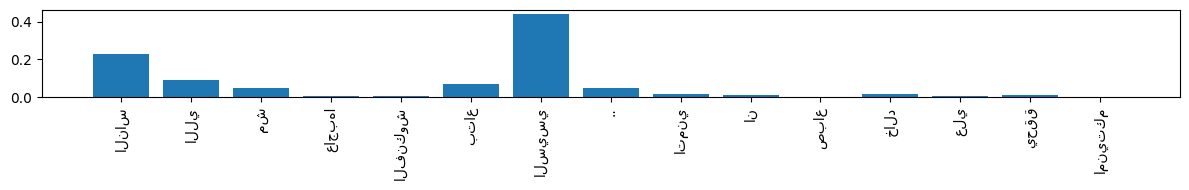

/tmp/ipykernel_48/2212963478.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


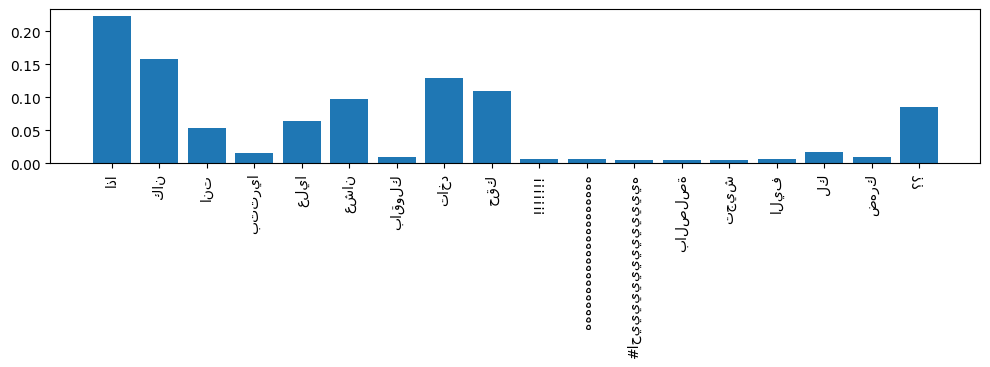

/tmp/ipykernel_48/2212963478.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


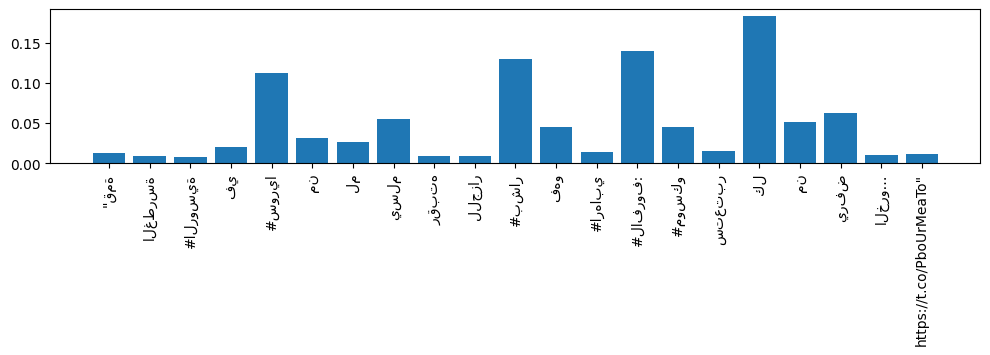

/tmp/ipykernel_48/2212963478.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


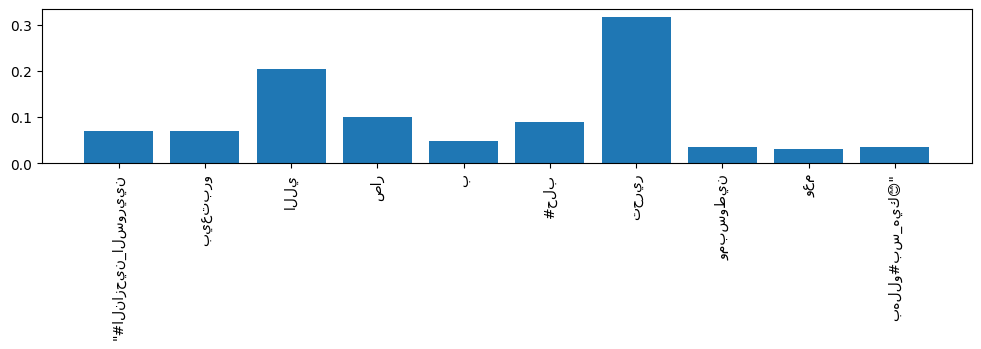

/tmp/ipykernel_48/2212963478.py:16: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


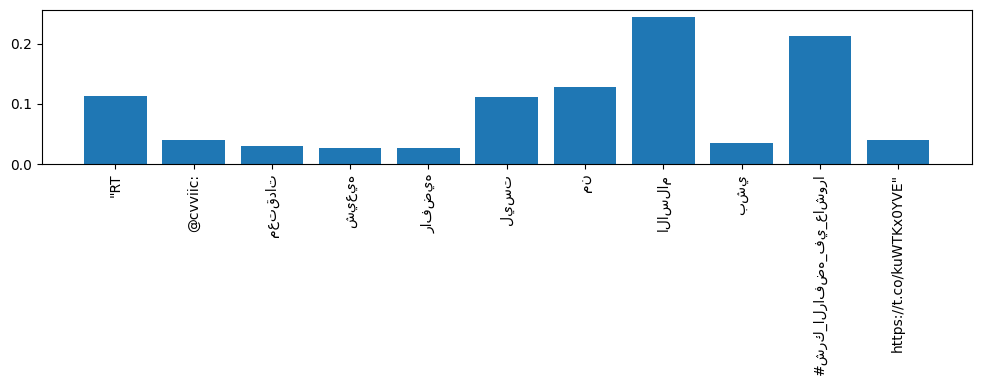

In [21]:
# Attention sur 5 tweets sarcastiques de validation (visualisation, pas preuve causale)
model = BiLSTM(attention=True).to(DEVICE)
model.load_state_dict(
    torch.load(ROOT / "results/C2_attention.pt", map_location=DEVICE, weights_only=True)
)
model.eval()
for tweet in val[val.y == 1].tweet.head(5):
    x = torch.tensor([encode(tweet)], device=DEVICE)
    with torch.no_grad():
        model(x)
    toks = words(tweet)[:MAXLEN]
    a = model.last_attention[0, : len(toks)].numpy()
    plt.figure(figsize=(12, 2))
    plt.bar(range(len(toks)), a)
    plt.xticks(range(len(toks)), toks, rotation=90)
    plt.tight_layout()
    plt.show()

# D — AraBERT gelé : CLS, mean pooling, BiLSTM + attention

In [22]:
from pathlib import Path
import os, sys, re, time, random, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
for d in ["data", "results", "predictions", "figures"]:
    (ROOT / d).mkdir(exist_ok=True)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
try:
    import torch

    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    DEVICE = "cpu"
print("Racine:", ROOT, "| GPU:", DEVICE)


def report(y, p, threshold=0.5):
    y = np.asarray(y).astype(int)
    p = np.asarray(p).astype(float)
    pred = (p >= threshold).astype(int)
    return dict(
        accuracy=accuracy_score(y, pred),
        precision=precision_score(y, pred, zero_division=0),
        recall=recall_score(y, pred, zero_division=0),
        f1_sarc=f1_score(y, pred, zero_division=0),
        macro_f1=f1_score(y, pred, average="macro", zero_division=0),
        pr_auc=average_precision_score(y, p),
    )


def best_threshold(y, p):
    t = np.linspace(0.05, 0.95, 91)
    return float(
        t[np.argmax([f1_score(y, np.asarray(p) >= x, zero_division=0) for x in t])]
    )


def save_result(
    model, split, y, p, threshold, seconds=0, params=0, seed=SEED, preprocess=""
):
    row = dict(
        model=model,
        split=split,
        seed=seed,
        threshold=threshold,
        seconds=round(seconds, 2),
        trainable_parameters=params,
        preprocess=preprocess,
        **report(y, p, threshold),
    )
    path = ROOT / "results/results.csv"
    old = pd.read_csv(path) if path.exists() else pd.DataFrame()
    pd.concat([old, pd.DataFrame([row])], ignore_index=True).to_csv(path, index=False)
    print(row)


def save_preds(model, seed, df, p, t):
    pd.DataFrame(
        {
            "id": df.id.to_numpy(),
            "y_true": df.y.to_numpy(),
            "y_pred": (np.asarray(p) >= t).astype(int),
            "prob_sarc": p,
        }
    ).to_csv(ROOT / f"predictions/{model}_seed{seed}.csv", index=False)

Racine: /kaggle/working | GPU: cuda


In [23]:
train = pd.read_csv(ROOT / "data/train.csv")
val = pd.read_csv(ROOT / "data/val.csv")
print(len(train), len(val))

11256 1255


In [24]:
import torch
from torch import nn
from transformers import AutoTokenizer, AutoModel
from sklearn.linear_model import LogisticRegression

NAME = "aubmindlab/bert-base-arabertv02-twitter"
tok = AutoTokenizer.from_pretrained(NAME)
enc = AutoModel.from_pretrained(NAME).to(DEVICE).eval()
for p in enc.parameters():
    p.requires_grad = False


@torch.no_grad()
def frozen_features(df):
    cls = []
    means = []
    states = []
    masks = []
    for i in range(0, len(df), 16):
        batch = tok(
            df.tweet.iloc[i : i + 16].tolist(),
            padding="max_length",
            truncation=True,
            max_length=96,
            return_tensors="pt",
        ).to(DEVICE)
        h = enc(**batch).last_hidden_state
        m = batch["attention_mask"].unsqueeze(-1)
        cls.append(h[:, 0].cpu())
        means.append(((h * m).sum(1) / m.sum(1).clamp(min=1)).cpu())
        states.append(h.cpu())
        masks.append(batch["attention_mask"].cpu())
    return torch.cat(cls), torch.cat(means), torch.cat(states), torch.cat(masks)


tr_cls, tr_mean, tr_h, tr_mask = frozen_features(train)
va_cls, va_mean, va_h, va_mask = frozen_features(val)
for name, x, z in [("CLS", tr_cls, va_cls), ("mean", tr_mean, va_mean)]:
    model = LogisticRegression(max_iter=1000, class_weight="balanced")
    model.fit(x.numpy(), train.y)
    p = model.predict_proba(z.numpy())[:, 1]
    t = best_threshold(val.y, p)
    save_result("D1_" + name, "val", val.y, p, t)
    np.save(ROOT / f"results/D1_{name}_val.npy", p)

config.json:   0%|          | 0.00/667 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/476 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/751k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.25M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  541MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: aubmindlab/bert-base-arabertv02-twitter
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'model': 'D1_CLS', 'split': 'val', 'seed': 42, 'threshold': 0.6, 'seconds': 0, 'trainable_parameters': 0, 'preprocess': '', 'accuracy': 0.8414342629482072, 'precision': 0.53, 'recall': 0.7327188940092166, 'f1_sarc': 0.6150870406189555, 'macro_f1': 0.7576187837314546, 'pr_auc': np.float64(0.6154454450498724)}
{'model': 'D1_mean', 'split': 'val', 'seed': 42, 'threshold': 0.6, 'seconds': 0, 'trainable_parameters': 0, 'preprocess': '', 'accuracy': 0.8446215139442231, 'precision': 0.5376712328767124, 'recall': 0.7235023041474654, 'f1_sarc': 0.6168958742632613, 'macro_f1': 0.7597222999502213, 'pr_auc': np.float64(0.6130179657534867)}


In [28]:
class FrozenAttention(nn.Module):
    def __init__(self, h=768):
        super().__init__()
        self.rnn = nn.LSTM(h, 64, bidirectional=True, batch_first=True)
        self.W = nn.Linear(128, 64)
        self.v = nn.Linear(64, 1, bias=False)
        self.fc = nn.Linear(128, 2)
        self.last_a = None

    def forward(self, x, mask):
        h, _ = self.rnn(x)
        a = (
            self.v(torch.tanh(self.W(h)))
            .squeeze(-1)
            .masked_fill(mask == 0, -1e9)
            .softmax(-1)
        )
        self.last_a = a.detach().cpu()
        return self.fc((a.unsqueeze(-1) * h).sum(1))


# make sure features are float32 (float64 would break the LSTM next)
tr_h, va_h = tr_h.float(), va_h.float()

head = FrozenAttention(tr_h.shape[-1]).to(DEVICE)
opt = torch.optim.AdamW(head.parameters(), lr=0.001)

n0 = int((train.y == 0).sum())
n1 = int((train.y == 1).sum())
weight = torch.tensor([1.0, n0 / max(1, n1)], dtype=torch.float32, device=DEVICE)
lossfn = nn.CrossEntropyLoss(weight=weight)

y_all = torch.as_tensor(train.y.to_numpy(), dtype=torch.long)

best = -1
for epoch in range(8):
    head.train()
    for ids in torch.randperm(len(train)).split(32):
        opt.zero_grad()
        logits = head(tr_h[ids].to(DEVICE), tr_mask[ids].to(DEVICE))
        loss = lossfn(logits, y_all[ids].to(DEVICE))
        loss.backward()
        opt.step()

    head.eval()
    with torch.no_grad():
        p = np.concatenate(
            [
                head(h.to(DEVICE), m.to(DEVICE)).softmax(-1)[:, 1].cpu().numpy()
                for h, m in zip(va_h.split(32), va_mask.split(32))
            ]
        )
    t = best_threshold(val.y, p)
    f = report(val.y, p, t)["f1_sarc"]
    print(epoch + 1, f)
    if f > best:
        best = f
        torch.save(head.state_dict(), ROOT / "results/D2_head.pt")
        np.save(ROOT / "results/D2_val.npy", p)

p_best = np.load(ROOT / "results/D2_val.npy")
save_result("D2_BiLSTM_attention", "val", val.y, p_best, best_threshold(val.y, p_best))

1 0.6756756756756757
2 0.6572008113590264
3 0.6574257425742575
4 0.6300813008130082
5 0.6313799621928167
6 0.652267818574514
7 0.6272189349112426
8 0.6237816764132553
{'model': 'D2_BiLSTM_attention', 'split': 'val', 'seed': 42, 'threshold': 0.7999999999999999, 'seconds': 0, 'trainable_parameters': 0, 'preprocess': '', 'accuracy': 0.8852589641434263, 'precision': 0.6607929515418502, 'recall': 0.6912442396313364, 'f1_sarc': 0.6756756756756757, 'macro_f1': 0.8029878862405484, 'pr_auc': np.float64(0.6972739939611731)}


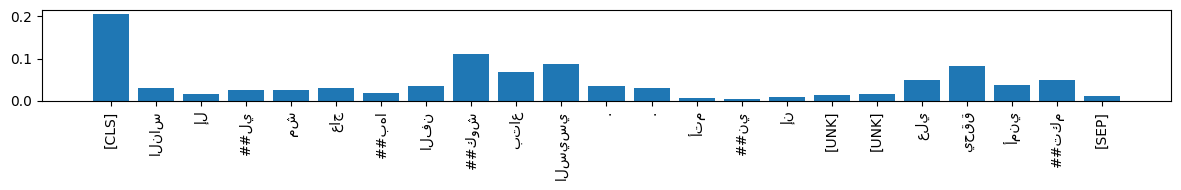

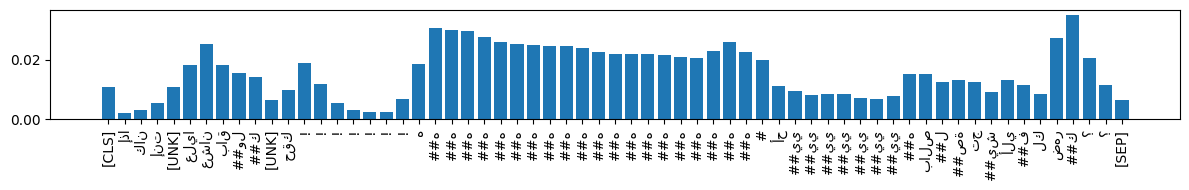

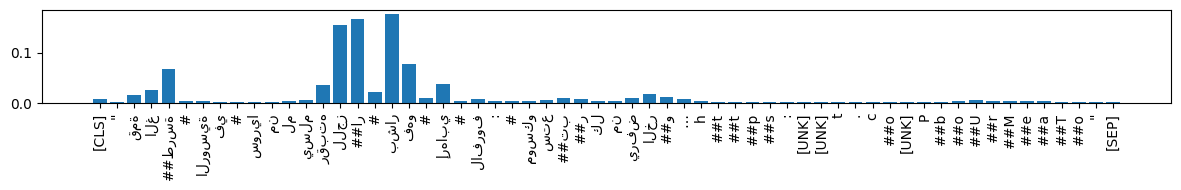

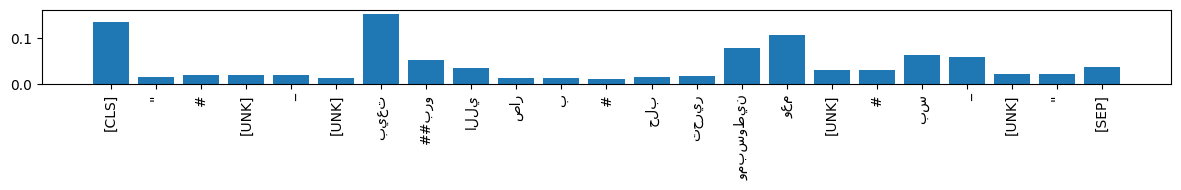

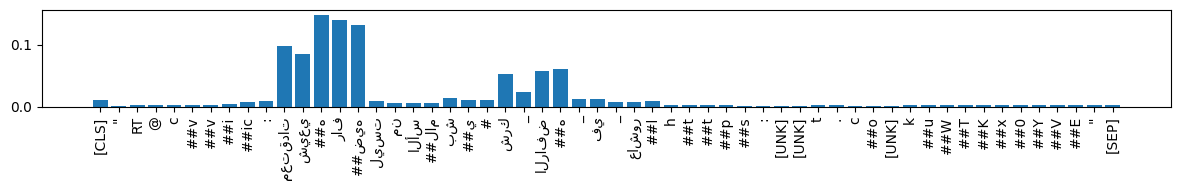

In [29]:
head.load_state_dict(
    torch.load(ROOT / "results/D2_head.pt", map_location=DEVICE, weights_only=True)
)
head.eval()
indices = np.flatnonzero(val.y.to_numpy() == 1)[:5]
for idx in indices:
    with torch.no_grad():
        head(va_h[idx : idx + 1].to(DEVICE), va_mask[idx : idx + 1].to(DEVICE))
    a = head.last_a[0].numpy()
    tokens = tok.convert_ids_to_tokens(
        tok(val.tweet.iloc[idx], padding="max_length", truncation=True, max_length=96)[
            "input_ids"
        ]
    )
    count = int(va_mask[idx].sum())
    plt.figure(figsize=(12, 2))
    plt.bar(range(count), a[:count])
    plt.xticks(range(count), tokens[:count], rotation=90)
    plt.tight_layout()
    plt.show()